# Intro

## Modules

In [5]:
import os
import sys

In [10]:
import numpy as np
import pandas as pd
import pymannkendall as mk

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.size'] = 10
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.size'] = 10
plt.rcParams['ytick.major.width'] = 2

plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

plt.rcParams['xtick.minor.size'] = 5
plt.rcParams['xtick.minor.width'] = 1
plt.rcParams['ytick.minor.size'] = 5
plt.rcParams['ytick.minor.width'] = 1

## Folders

In [ ]:
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
SDGS_CLAUDE_DIR = os.path.join(PROJECT_ROOT, 'sdgs_claude')
RESULTS_DIR = os.path.join(SDGS_CLAUDE_DIR, 'results')
SCORES_DIR = os.path.join(RESULTS_DIR, 'scores')

## Standards

In [16]:
sdg_helper={'01':'No Poverty', 
 '02': 'Zero hunger', 
 '03': 'Good health and well-being', 
 '04': 'Quality education',
 '05': 'Gender equality',
 '06': 'Clean water and sanitation',
 '07': 'Affordable and clean energy',
 '08': 'Decent work and economic growth',
 '09': 'Industry, Innovation, Technology and Infrastructure',
 '10': 'Reduced inequality',
 '11': 'Sustainable cities and communities',
 '12': 'Responsible consumption and production',
 '13': 'Climate action',
 '14': 'Life below water',
 '15': 'Life on land',
 '16': 'Peace, justice and strong institutions',
 '17': 'Partnerships for the goals'
}

In [29]:
sdg_color_list = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red',
    'tab:purple',
    'tab:brown',
    'tab:pink',
    'tab:gray',
    'tab:olive',
    'tab:cyan',
    'darkblue',
    'gold',
    'crimson',
    'darkgreen',
    'darkorange',
    'deeppink',
    'firebrick',
]
len(sdg_color_list)

17

In [19]:
_lss=['-', '--', ':', '-.']
_markers=['^', 's', 'p', 'H', '8', 'X', 'D', '*', 'o']

## Functions

In [33]:
def fdr_th(p_vals, alpha):
    _aux=np.sort(p_vals)
    fdr_ths=np.arange(1, 1+len(_aux))*alpha/len(_aux)
    fdr_mask=_aux<=fdr_ths
    if np.sum(fdr_mask)>0:
        return fdr_ths[fdr_mask][-1]
    else:
        return 0.

# Mann-Kendall and LLM

In [9]:
llm = pd.read_csv(os.path.join(SCORES_DIR, 'llm_adherence_by_report_sdg.csv'))

In [37]:
p_values=[]
for sdg in range(1, 18):
    series = llm[llm['sdg'] == sdg].groupby('year')['adherence_score'].mean().sort_index()
    p_values.append(mk.original_test(series.values).p)
fdr_alpha=fdr_th(p_values, 0.05)

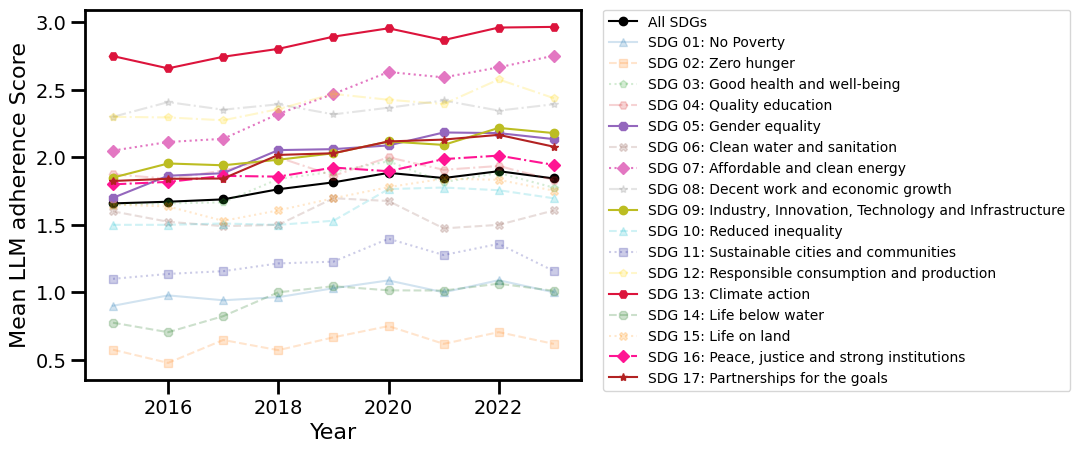

In [72]:
#fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 6), sharex=True, sharey=True)
#by_calendar_year = llm.groupby('year')['adherence_score'].mean().sort_index()
plt.plot(by_calendar_year.index, by_calendar_year.values, marker='o', label='All SDGs', color='black')
for sdg in range(1, 18):
    series = llm[llm['sdg'] == sdg].groupby('year')['adherence_score'].mean().sort_index()
    if p_values[sdg-1] <= fdr_alpha:
        plt.plot(series.index, series.values, label=f'SDG {sdg:02d}: {sdg_helper[f"{sdg:02d}"]}', alpha=1.0, color=sdg_color_list[sdg-1], ls=_lss[(sdg-1) % len(_lss)], marker=_markers[(sdg-1) %len(_markers)])
    else:
        plt.plot(series.index, series.values, label=f'SDG {sdg:02d}: {sdg_helper[f"{sdg:02d}"]}', alpha=0.2, color=sdg_color_list[sdg-1], ls=_lss[(sdg-1) % len(_lss)], marker=_markers[(sdg-1) %len(_markers)])
plt.legend(loc=1, bbox_to_anchor=(2.0, 1.02))
plt.xlim(2014.5, 2023.5)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Mean LLM adherence Score', fontsize=16)
plt.savefig('./NewPlots/llm_vs_year_vs_sdgs.png', bbox_inches='tight', dpi=300)
plt.show()